# Brownian motion in finance

These are my working notes from learning stochastic calculus for quant finance. My background is physics (particle physics, lots of Python and statistics), so I already knew random walks and diffusion from the physics side, but not how the finance people use them. I wanted to go through everything with actual simulations instead of just reading Shreve and nodding along.

Everything is checked numerically, so the cells should be run top to bottom. Most of the interesting stuff happens when you change parameters and re-run.

Rough outline:

1. Random walk -> Brownian motion (CLT / Donsker)
2. Definition and basic properties
3. Quadratic variation, $(dW)^2 = dt$
4. Martingales
5. Itô integral and Itô's lemma
6. Arithmetic and geometric BM, volatility drag
7. Simulating SDEs (Euler-Maruyama, Milstein, exact)
8. Estimating $\mu$ and $\sigma$ from data
9. Risk-neutral pricing and Black-Scholes
10. Monte Carlo pricing + variance reduction
11. Delta hedging
12. Reflection principle, first passage times
13. Ornstein-Uhlenbeck / Vasicek
14. Where BM fails
15. Some interview-style problems
16. Summary + reading list

In [1]:
# !pip install numpy scipy matplotlib

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(seed=42)  # fixed seed so results are reproducible

plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## 1. From coin flips to Brownian motion

Simplest possible random process: flip a fair coin each step, +1 for heads, -1 for tails.

$$S_n = \xi_1 + \xi_2 + \dots + \xi_n, \qquad \xi_i = \pm 1 \text{ with probability } \tfrac12 .$$

Each step has mean 0 and variance 1, so $\mathbb{E}[S_n]=0$ and $\mathrm{Var}(S_n)=n$.

Now squeeze $n$ steps into $[0, 1]$, so each step takes $\Delta t = 1/n$, and shrink the step size to $\sqrt{\Delta t}$. The reason it has to be $\sqrt{\Delta t}$ (and not $\Delta t$) is that we want the variance at time $t$ to be $t$ no matter what $n$ is:

$$\mathrm{Var}\big(W^{(n)}_t\big) = \underbrace{(t/\Delta t)}_{\#\text{steps}} \times \underbrace{(\sqrt{\Delta t})^2}_{\text{var per step}} = t .$$

With steps of size $\Delta t$ the variance goes like $t\,\Delta t \to 0$ and the walk flattens out. With anything bigger than $\sqrt{\Delta t}$ it blows up. So $\sqrt{\Delta t}$ is the only scaling that gives something non-trivial in the limit. This is the same square-root-of-time you get in diffusion, and it's why volatility over a horizon $T$ scales like $\sigma\sqrt{T}$.

As $n\to\infty$ the rescaled walk converges to Brownian motion $W_t$ (Donsker's theorem, basically a CLT for whole paths).

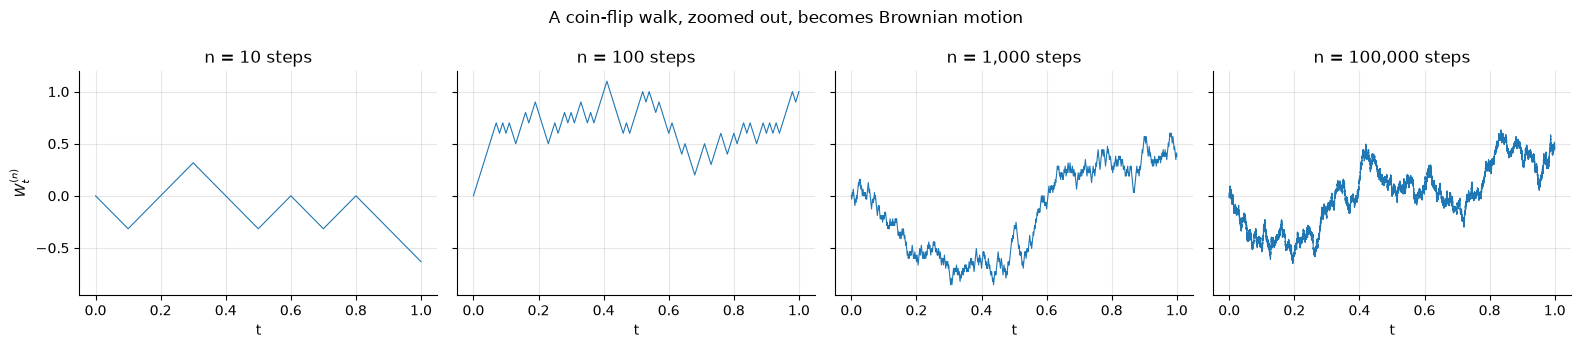

In [4]:
def scaled_random_walk(n_steps, T=1.0):
    # +-1 coin flip walk, rescaled to [0, T] so that Var(W_t) = t
    dt = T / n_steps
    steps = rng.choice([-1.0, 1.0], size=n_steps) * np.sqrt(dt)
    t = np.linspace(0, T, n_steps + 1)
    W = np.concatenate([[0.0], np.cumsum(steps)])
    return t, W

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, n in zip(axes, [10, 100, 1_000, 100_000]):
    t, W = scaled_random_walk(n)
    ax.plot(t, W, lw=0.8)
    ax.set_title(f"n = {n:,} steps")
    ax.set_xlabel("t")
axes[0].set_ylabel("$W^{(n)}_t$")
fig.suptitle("A coin-flip walk, zoomed out, becomes Brownian motion")
plt.tight_layout()
plt.show()

By the CLT the endpoint $W^{(n)}_1 = S_n/\sqrt{n}$ should be roughly $\mathcal{N}(0,1)$ for large $n$, even though each step is just a coin flip. Checking with 50k walks.

Small shortcut: the number of heads in $n$ flips is $\text{Binomial}(n, \tfrac12)$ and $S_n = 2\cdot\#\text{heads} - n$, so I can sample the endpoint directly without generating every step.

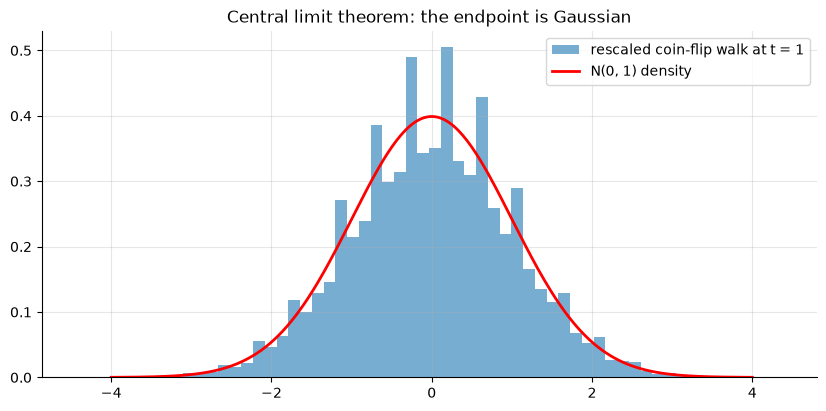

sample mean     = +0.0041   (theory 0)
sample variance = 1.0091    (theory 1)


In [4]:
n, n_paths = 1_000, 50_000
endpoints = (2 * rng.binomial(n, 0.5, size=n_paths) - n) / np.sqrt(n)

xs = np.linspace(-4, 4, 300)
plt.hist(endpoints, bins=60, density=True, alpha=0.6, label="rescaled coin-flip walk at t = 1")
plt.plot(xs, stats.norm.pdf(xs), "r", lw=2, label="N(0, 1) density")
plt.title("Central limit theorem: the endpoint is Gaussian")
plt.legend()
plt.show()

print(f"sample mean     = {endpoints.mean():+.4f}   (theory 0)")
print(f"sample variance = {endpoints.var():.4f}    (theory 1)")

Why this matters for prices: a price move is the sum of lots of small, more or less independent trades and bits of news. Summing many small independent shocks gives something Gaussian with spread growing like $\sqrt{t}$, which is the (idealised) argument for modelling log-prices with BM. Fun fact: Bachelier did exactly this in his 1900 thesis on the Paris stock exchange, five years before Einstein's Brownian motion paper.

## 2. Definition and basic properties

A standard Brownian motion (Wiener process) $W = (W_t)_{t\ge 0}$ satisfies:

1. $W_0 = 0$.
2. Independent increments: for $0 \le t_0 < t_1 < \dots < t_k$ the increments $W_{t_1}-W_{t_0},\; W_{t_2}-W_{t_1},\dots$ are independent.
3. Gaussian, stationary increments: $W_t - W_s \sim \mathcal{N}(0,\, t-s)$ for $s<t$.
4. Continuous paths.

Things that follow from this:

| Property | Formula |
|---|---|
| Mean | $\mathbb{E}[W_t] = 0$ |
| Variance | $\mathrm{Var}(W_t) = t$, so std is $\sqrt{t}$ |
| Covariance | $\mathrm{Cov}(W_s, W_t) = \min(s, t)$ |
| Scaling | $\big(\tfrac{1}{\sqrt{c}} W_{ct}\big)_{t\ge0}$ is again a BM |
| Roughness | continuous but nowhere differentiable |

Covariance proof (this comes up a lot): for $s<t$, write $W_t = W_s + (W_t - W_s)$. Then
$\mathbb{E}[W_s W_t] = \mathbb{E}[W_s^2] + \mathbb{E}[W_s(W_t-W_s)] = s + \mathbb{E}[W_s]\,\mathbb{E}[W_t - W_s] = s.$
The trick of splitting into "what I already know" plus an independent increment shows up everywhere later.

### Simulating it
On a grid with step $\Delta t$, property 3 says $\Delta W \sim \mathcal{N}(0, \Delta t)$, i.e. $\Delta W = \sqrt{\Delta t}\, Z$ with $Z \sim \mathcal{N}(0,1)$. Cumulative sum gives the path. This is exact at the grid points, no approximation involved.

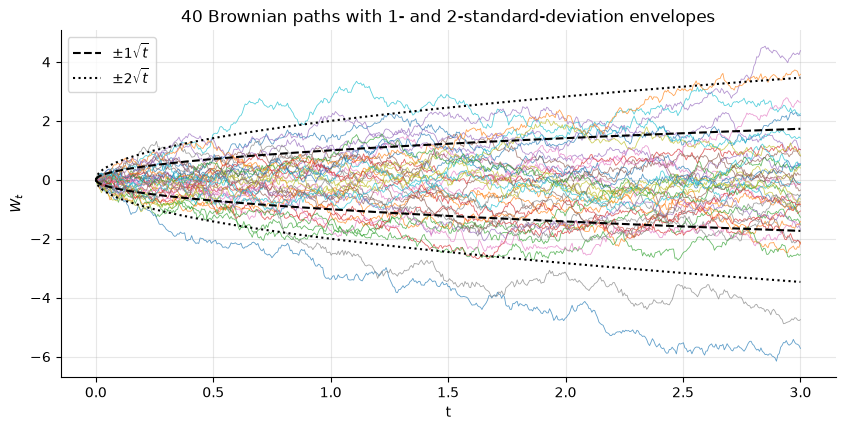

In [8]:
def brownian_paths(n_paths, n_steps, T=1.0):
    # t has shape (n_steps+1,), W has shape (n_paths, n_steps+1)
    dt = T / n_steps
    dW = rng.normal(0.0, np.sqrt(dt), size=(n_paths, n_steps))
    W = np.concatenate([np.zeros((n_paths, 1)), np.cumsum(dW, axis=1)], axis=1)
    t = np.linspace(0.0, T, n_steps + 1)
    return t, W

t, W = brownian_paths(n_paths=10_000, n_steps=500, T=3.0)

plt.plot(t, W[:40].T, lw=0.6, alpha=0.7)
for k, style in [(1, "--"), (2, ":")]:
    plt.plot(t,  k * np.sqrt(t), "k" + style, lw=1.5, label=rf"$\pm{k}\sqrt{{t}}$")
    plt.plot(t, -k * np.sqrt(t), "k" + style, lw=1.5)
plt.title("40 Brownian paths with 1- and 2-standard-deviation envelopes")
plt.xlabel("t"); plt.ylabel("$W_t$")
plt.legend()
plt.show()

Checking the properties from the table on the 10k paths:

In [10]:
def idx(time):  # grid index for a given time
    return int(round(time / (t[1] - t[0])))

print("Mean and variance at several times")
for s in [0.1, 0.25, 0.5, 1.0]:
    x = W[:, idx(s)]
    print(f"  t = {s:<5} mean = {x.mean():+.4f} (0)   var = {x.var():.4f} ({s})")

s_, t_ = 0.3, 0.8
cov = np.cov(W[:, idx(s_)], W[:, idx(t_)])[0, 1]
print(f"\nCov(W_{s_}, W_{t_}) = {cov:.4f}   theory min(s,t) = {min(s_, t_)}")

inc1 = W[:, idx(0.5)] - W[:, idx(0.2)]   # increment over [0.2, 0.5]
inc2 = W[:, idx(0.9)] - W[:, idx(0.5)]   # increment over [0.5, 0.9]  (non-overlapping)
inc3 = W[:, idx(0.7)] - W[:, idx(0.4)]   # increment over [0.4, 0.7]  (overlaps inc1)
print(f"\nCorr of non-overlapping increments = {np.corrcoef(inc1, inc2)[0, 1]:+.4f}  (theory 0)")
print(f"Corr of overlapping increments     = {np.corrcoef(inc1, inc3)[0, 1]:+.4f}  "
      f"(theory overlap/sqrt(len1*len2) = {0.1 / np.sqrt(0.3 * 0.3):.4f})")

Mean and variance at several times
  t = 0.1   mean = -0.0000 (0)   var = 0.1017 (0.1)
  t = 0.25  mean = -0.0046 (0)   var = 0.2506 (0.25)
  t = 0.5   mean = -0.0114 (0)   var = 0.4973 (0.5)
  t = 1.0   mean = -0.0196 (0)   var = 1.0026 (1.0)

Cov(W_0.3, W_0.8) = 0.3003   theory min(s,t) = 0.3

Corr of non-overlapping increments = -0.0043  (theory 0)
Corr of overlapping increments     = +0.3191  (theory overlap/sqrt(len1*len2) = 0.3333)


Scaling / self-similarity: if you zoom in by $c$ in time and $\sqrt{c}$ in space, the path looks statistically the same. A one-day chart and a one-year chart of a random walk look alike once the axes are rescaled.

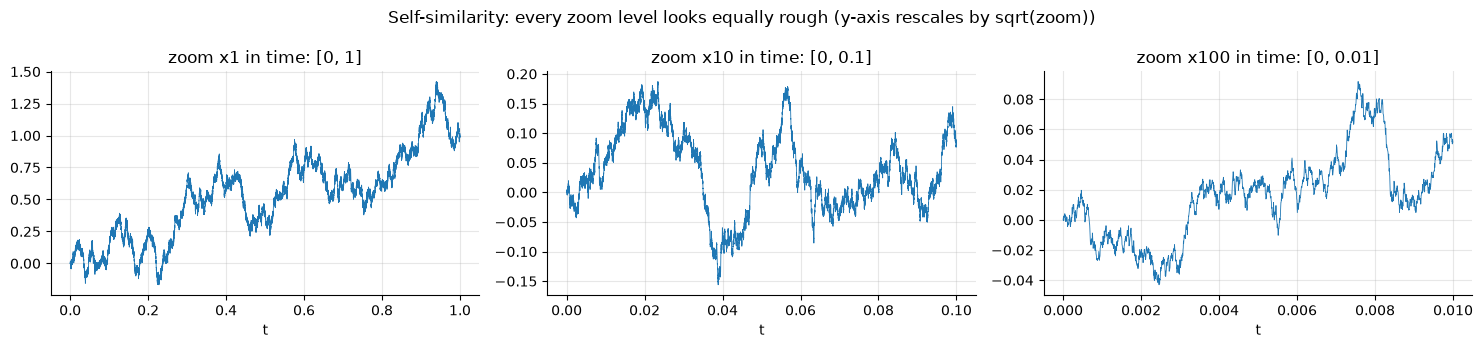

In [11]:
t_fine, W_one = brownian_paths(1, 200_000, T=1.0)
W_one = W_one[0]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, zoom in zip(axes, [1, 10, 100]):
    m = len(t_fine) // zoom
    ax.plot(t_fine[:m], W_one[:m], lw=0.6)
    ax.set_title(f"zoom x{zoom} in time: [0, {1/zoom:g}]")
    ax.set_xlabel("t")
fig.suptitle("Self-similarity: every zoom level looks equally rough (y-axis rescales by sqrt(zoom))")
plt.tight_layout()
plt.show()

Quick self-check:
1. $\mathrm{Var}(W_3 - W_1)$?
2. $\mathrm{Var}(W_1 + W_2)$?

<details><summary>answers</summary>

1. $W_3 - W_1 \sim \mathcal N(0, 2)$, so 2.
2. $\mathrm{Var}(W_1) + \mathrm{Var}(W_2) + 2\,\mathrm{Cov}(W_1, W_2) = 1 + 2 + 2 = 5$. Or write $W_1 + W_2 = 2W_1 + (W_2 - W_1)$, variance $4 + 1 = 5$.
</details>

## 3. Quadratic variation: why $(dW)^2 = dt$

This is the part that makes stochastic calculus different from normal calculus.

Split $[0, T]$ into $n$ steps of size $\Delta t = T/n$ and look at two sums over the increments $\Delta W_i$:

* total variation $\sum_i |\Delta W_i|$ (total up-and-down distance)
* quadratic variation $\sum_i (\Delta W_i)^2$

For a smooth $f$, $\Delta f \approx f'\,\Delta t$, so $\sum (\Delta f)^2 \approx \sum f'^2 \Delta t^2 \to 0$. Smooth functions have zero quadratic variation.

For BM each $(\Delta W_i)^2$ has mean $\Delta t$ and variance $2\Delta t^2$, so
$$\mathbb{E}\Big[\sum_i (\Delta W_i)^2\Big] = n\,\Delta t = T, \qquad \mathrm{Var}\Big[\sum_i (\Delta W_i)^2\Big] = n \cdot 2\Delta t^2 = \frac{2T^2}{n} \to 0.$$
So the sum converges to the deterministic number $T$. On the other hand $\mathbb E|\Delta W_i| = \sqrt{2\Delta t/\pi}$, so the total variation is about $\sqrt{2nT/\pi} \to \infty$. A Brownian path has infinite length on any interval.

The rules that come out of this:
$$(dW_t)^2 = dt, \qquad dW_t\,dt = 0, \qquad (dt)^2 = 0$$

In [12]:
T = 1.0
print(f"{'n steps':>10} | {'sum (dW)^2':>11} | {'sum |dW|':>10} | {'sqrt(2nT/pi)':>12} | {'smooth fn QV':>12}")
print("-" * 68)
for n in [10, 100, 1_000, 10_000, 100_000, 1_000_000]:
    dW = rng.normal(0, np.sqrt(T / n), size=n)
    grid = np.linspace(0, T, n + 1)
    df = np.diff(np.sin(2 * np.pi * grid))  # smooth function to compare against
    print(f"{n:>10,} | {np.sum(dW**2):11.4f} | {np.sum(np.abs(dW)):10.2f} | "
          f"{np.sqrt(2 * n * T / np.pi):12.2f} | {np.sum(df**2):12.2e}")

   n steps |  sum (dW)^2 |   sum |dW| | sqrt(2nT/pi) | smooth fn QV
--------------------------------------------------------------------
        10 |      1.1003 |       2.89 |         2.52 |     1.91e+00
       100 |      1.1882 |       8.86 |         7.98 |     1.97e-01
     1,000 |      1.0544 |      25.73 |        25.23 |     1.97e-02
    10,000 |      0.9968 |      79.76 |        79.79 |     1.97e-03
   100,000 |      0.9983 |     251.69 |       252.31 |     1.97e-04
 1,000,000 |      0.9992 |     798.17 |       797.88 |     1.97e-05


So the BM quadratic variation sits at $T = 1$, the total variation grows like $\sqrt n$, and the smooth function's QV goes to zero, as expected.

In finance terms: if log-prices follow $\sigma W_t$, the sum of squared log-returns over a day converges to $\sigma^2 \times$ (length of day) as you sample more often. That sum is the realized variance, which is how people measure vol from high-frequency data. Section 8 follows up on this: vol can be estimated very precisely, drift can't.

## 4. Martingales

$M_t$ is a martingale if the best forecast of its future value, given the information up to now ($\mathcal F_s$), is just its current value:
$$\mathbb{E}[M_t \mid \mathcal{F}_s] = M_s \quad \text{for } s \le t.$$

Think "fair game": you can't make a positive expected profit using only past information. The fundamental theorem of asset pricing says that with no arbitrage, discounted prices are martingales under some measure $\mathbb{Q}$ (the risk-neutral measure). That's why everything in pricing ends up being phrased in terms of martingales.

Three standard examples:

| Martingale | Why |
|---|---|
| $W_t$ | $\mathbb E[W_t \mid \mathcal F_s] = W_s + \mathbb E[W_t - W_s] = W_s$ |
| $W_t^2 - t$ | $W_t^2 = (W_s + \Delta)^2$ with $\Delta = W_t - W_s$, so $\mathbb E[\,\cdot \mid \mathcal F_s] = W_s^2 + 0 + (t-s)$ |
| $\exp\!\big(\sigma W_t - \tfrac12\sigma^2 t\big)$ | from $\mathbb E[e^{\sigma Z}] = e^{\sigma^2/2}$ for $Z\sim\mathcal N(0,1)$; this is the one behind GBM |

$W_t^2$ by itself is not a martingale, it drifts up at rate 1. Subtracting $t$ (the compensator) fixes that.

A martingale has constant expectation, $\mathbb E[M_t] = M_0$. That's necessary but not sufficient, but it's an easy sanity check on the paths from before:

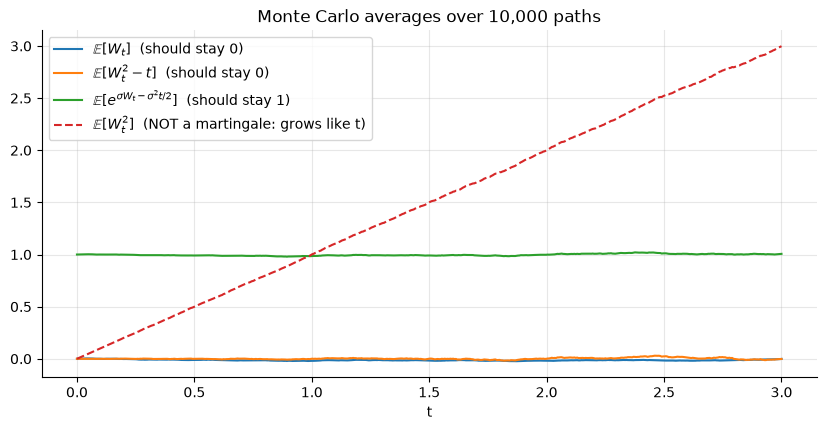

In [13]:
sigma = 0.8
times = t
mart_W   = W.mean(axis=0)
mart_W2  = (W**2 - times).mean(axis=0)
not_mart = (W**2).mean(axis=0)
mart_exp = np.exp(sigma * W - 0.5 * sigma**2 * times).mean(axis=0)

plt.plot(times, mart_W,   label=r"$\mathbb{E}[W_t]$  (should stay 0)")
plt.plot(times, mart_W2,  label=r"$\mathbb{E}[W_t^2 - t]$  (should stay 0)")
plt.plot(times, mart_exp, label=r"$\mathbb{E}[e^{\sigma W_t - \sigma^2 t/2}]$  (should stay 1)")
plt.plot(times, not_mart, "--", label=r"$\mathbb{E}[W_t^2]$  (NOT a martingale: grows like t)")
plt.xlabel("t"); plt.title("Monte Carlo averages over 10,000 paths")
plt.legend()
plt.show()

## 5. Itô integral and Itô's lemma

### 5.1 Integrating against BM
If I hold $\Delta_t$ shares and the price moves by $dS_t$, the gain is $\Delta_t\, dS_t$, and the total is $\int_0^T \Delta_t\, dS_t$. Since Brownian paths have infinite total variation, the usual Riemann-Stieltjes integral doesn't work. It has to be defined as a limit of sums, and it matters where in each interval you evaluate the integrand.

The Itô integral uses the left endpoint:
$$\int_0^T H_t\, dW_t = \lim_{n\to\infty} \sum_{i} H_{t_i}\,\big(W_{t_{i+1}} - W_{t_i}\big).$$
This makes sense financially: you pick your position $H_{t_i}$ before you see the next price move. Anything else would be using future information.

### 5.2 Example: $\int_0^T W_t\, dW_t$
Normal calculus would give $\tfrac12 W_T^2$. The Itô answer is
$$\int_0^T W_t\, dW_t = \tfrac12 W_T^2 - \tfrac12 T.$$
The extra $-\tfrac12T$ comes from the identity $W_{i}(W_{i+1}-W_i) = \tfrac12\big(W_{i+1}^2 - W_i^2\big) - \tfrac12 (W_{i+1}-W_i)^2$. Summing, the first part telescopes to $\tfrac12W_T^2$ and the second is $-\tfrac12\times$ (quadratic variation) $\to -\tfrac12 T$. Checking numerically, and comparing with the midpoint (Stratonovich) rule:

In [14]:
n, T = 1_000_000, 1.0
dW = rng.normal(0, np.sqrt(T / n), size=n)
Wp = np.concatenate([[0.0], np.cumsum(dW)])

ito   = np.sum(Wp[:-1] * dW)                     # left endpoint
strat = np.sum(0.5 * (Wp[:-1] + Wp[1:]) * dW)    # midpoint (average of endpoints)
WT = Wp[-1]

print(f"W_T = {WT:+.4f}")
print(f"Itô sum (left point)        = {ito:+.5f}   formula (W_T^2 - T)/2 = {(WT**2 - T) / 2:+.5f}")
print(f"Stratonovich sum (midpoint) = {strat:+.5f}   formula  W_T^2 / 2    = {WT**2 / 2:+.5f}")

W_T = +1.0119
Itô sum (left point)        = +0.01319   formula (W_T^2 - T)/2 = +0.01194
Stratonovich sum (midpoint) = +0.51194   formula  W_T^2 / 2    = +0.51194


They differ by exactly $\tfrac12 T$, which is the $(dW)^2 = dt$ thing again. Also $\mathbb E\big[\int H\,dW\big] = 0$ for Itô integrals (they're martingales), consistent with $\mathbb E[\tfrac12W_T^2 - \tfrac12T] = 0$.

### 5.3 Itô's lemma
Let $dX_t = \mu_t\, dt + \sigma_t\, dW_t$ and $f(t, x)$ smooth. Taylor expand to second order:
$$df = f_t\,dt + f_x\,dX + \tfrac12 f_{xx}\,(dX)^2 + \dots$$
Normally $(dX)^2$ is negligible, but here $(dX)^2 = \sigma^2 (dW)^2 + (dt\,dW,\ dt^2 \text{ terms}) = \sigma^2\,dt$, which is the same order as $dt$, so it stays:

$$df(t, X_t) = \Big(f_t + \mu f_x + \tfrac12\sigma^2 f_{xx}\Big)dt + \sigma f_x\, dW_t$$

Example: $f(x) = x^2$, $X = W$ ($\mu=0,\sigma=1$) gives $d(W_t^2) = 2W_t\,dW_t + dt$, which integrates back to the result in 5.2. Checking along one path:

In [15]:
lhs = WT**2                         # integral of d(W^2) from 0 to T
rhs = 2 * np.sum(Wp[:-1] * dW) + T  # 2 * integral of W dW + integral of dt
print(f"W_T^2               = {lhs:.5f}")
print(f"2 * int W dW + T    = {rhs:.5f}")
print(f"without the Itô term = {rhs - T:.5f}   <- ordinary chain rule gets this wrong")

W_T^2               = 1.02389
2 * int W dW + T    = 1.02638
without the Itô term = 0.02638   <- ordinary chain rule gets this wrong


Exercise: use Itô's lemma on $e^{W_t}$ and $t\,W_t$.

<details><summary>answers</summary>

* $f(x) = e^x$: $f_x = f_{xx} = e^x$, so $d(e^{W_t}) = e^{W_t}dW_t + \tfrac12 e^{W_t}dt$. Because of the drift, $e^{W_t}$ isn't a martingale but $e^{W_t - t/2}$ is.
* $f(t,x) = tx$: $f_t = x$, $f_x = t$, $f_{xx}=0$, so $d(tW_t) = W_t\,dt + t\,dW_t$. No correction since $f_{xx}=0$.
</details>

## 6. Arithmetic and geometric Brownian motion

### 6.1 Arithmetic BM (Bachelier)
$$dX_t = \mu\,dt + \sigma\,dW_t \quad\Longrightarrow\quad X_t = X_0 + \mu t + \sigma W_t \sim \mathcal N(X_0 + \mu t,\ \sigma^2 t).$$
Drift plus noise. As a stock model it has problems: $X_t$ can go negative, and a \$1 move means the same thing for a \$5 stock and a \$500 stock. It does get used where negative values are OK, like spreads and interest rates (the "normal" model for rates options became popular once rates went negative in the 2010s).

### 6.2 Geometric BM (Black-Scholes)
Instead, model percentage changes as Brownian:
$$\frac{dS_t}{S_t} = \mu\,dt + \sigma\,dW_t .$$
$\mu$ is the expected return, $\sigma$ the volatility (std of returns per $\sqrt{\text{year}}$).

Solving with Itô, $f(S) = \ln S$, $f_S = 1/S$, $f_{SS} = -1/S^2$:
$$d\ln S_t = \frac{1}{S_t}dS_t - \frac12\frac{1}{S_t^2}(dS_t)^2 = (\mu\,dt + \sigma\,dW_t) - \tfrac12\sigma^2 dt = \big(\mu - \tfrac12\sigma^2\big)dt + \sigma\,dW_t.$$
Constant coefficients on the right, so just integrate:
$$S_t = S_0 \exp\!\Big(\big(\mu - \tfrac12\sigma^2\big)t + \sigma W_t\Big)$$
$\ln S_t$ is Gaussian, $S_t$ is lognormal and always positive.

### 6.3 Mean vs median (volatility drag)
* Mean: $\mathbb E[S_t] = S_0 e^{\mu t}$ (using $\mathbb E[e^{\sigma W_t}] = e^{\sigma^2 t/2}$).
* Median (the "typical" path): $S_0 e^{(\mu - \sigma^2/2)t}$.

The $\sigma^2/2$ gap is called volatility drag. Simple way to see it: lose 50% then gain 50% and you're at 75%, not 100%. With $\mu = 5\%$ and $\sigma = 40\%$ the median growth rate is $5\% - 8\% = -3\%$ per year. The average outcome grows while the typical outcome shrinks, because the mean is held up by a small number of huge winners.

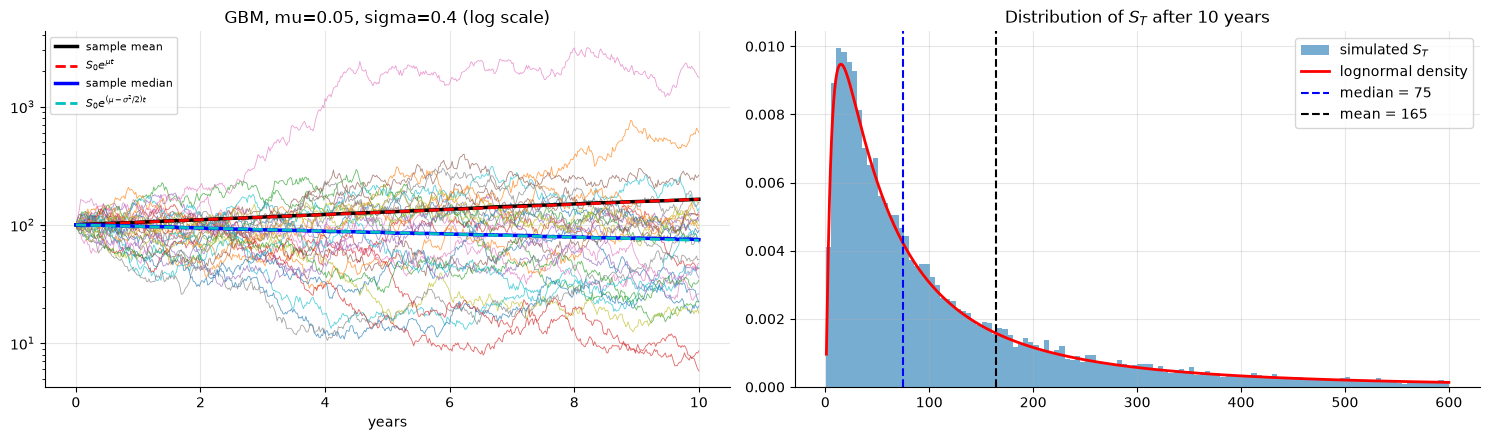

Theory: mean = 164.9, median = 74.1
Fraction of paths that LOST money over 10 years: 59.1%


In [16]:
S0, mu, sigma, T = 100.0, 0.05, 0.40, 10.0
n_paths, n_steps = 20_000, 520           # weekly steps for 10 years
dt = T / n_steps

Z = rng.standard_normal((n_paths, n_steps))
logS = np.log(S0) + np.cumsum((mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z, axis=1)
S = np.exp(np.concatenate([np.full((n_paths, 1), np.log(S0)), logS], axis=1))
tt = np.linspace(0, T, n_steps + 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(tt, S[:30].T, lw=0.6, alpha=0.7)
axes[0].plot(tt, S.mean(axis=0), "k", lw=2.5, label="sample mean")
axes[0].plot(tt, S0 * np.exp(mu * tt), "r--", lw=2, label=r"$S_0 e^{\mu t}$")
axes[0].plot(tt, np.median(S, axis=0), "b", lw=2.5, label="sample median")
axes[0].plot(tt, S0 * np.exp((mu - 0.5 * sigma**2) * tt), "c--", lw=2,
             label=r"$S_0 e^{(\mu-\sigma^2/2)t}$")
axes[0].set_yscale("log"); axes[0].set_title(f"GBM, mu={mu}, sigma={sigma} (log scale)")
axes[0].set_xlabel("years"); axes[0].legend(fontsize=8)

ST = S[:, -1]
x = np.linspace(1, 600, 600)
lognorm = stats.lognorm(s=sigma * np.sqrt(T), scale=S0 * np.exp((mu - 0.5 * sigma**2) * T))
axes[1].hist(ST[ST < 600], bins=120, density=True, alpha=0.6, label="simulated $S_T$")
axes[1].plot(x, lognorm.pdf(x), "r", lw=2, label="lognormal density")
axes[1].axvline(np.median(ST), color="b", ls="--", label=f"median = {np.median(ST):.0f}")
axes[1].axvline(ST.mean(), color="k", ls="--", label=f"mean = {ST.mean():.0f}")
axes[1].set_title(f"Distribution of $S_T$ after {T:g} years"); axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Theory: mean = {S0 * np.exp(mu * T):.1f}, median = {S0 * np.exp((mu - 0.5 * sigma**2) * T):.1f}")
print(f"Fraction of paths that LOST money over {T:g} years: {np.mean(ST < S0):.1%}")

So for a long-horizon investor the growth rate that actually matters is $\mu - \sigma^2/2$, not $\mu$. Lowering vol at the same expected return increases compounded growth, which is part of why risk management and diversification matter so much.

## 7. Simulating SDEs: Euler-Maruyama, Milstein, exact

Most SDEs $dX = a(X)\,dt + b(X)\,dW$ don't have closed-form solutions, so you discretise. The two standard schemes:

* Euler-Maruyama: $X_{k+1} = X_k + a(X_k)\Delta t + b(X_k)\Delta W_k$
* Milstein: Euler plus the correction $\tfrac12\, b(X_k)\,b'(X_k)\big((\Delta W_k)^2 - \Delta t\big)$

For GBM ($a = \mu S$, $b = \sigma S$, $b' = \sigma$) the exact solution is known, so I can measure the strong error $\mathbb E\,|X^{\text{scheme}}_T - X^{\text{exact}}_T|$ using the same Brownian increments for both. Expected: Euler goes like $\Delta t^{1/2}$, Milstein like $\Delta t$.

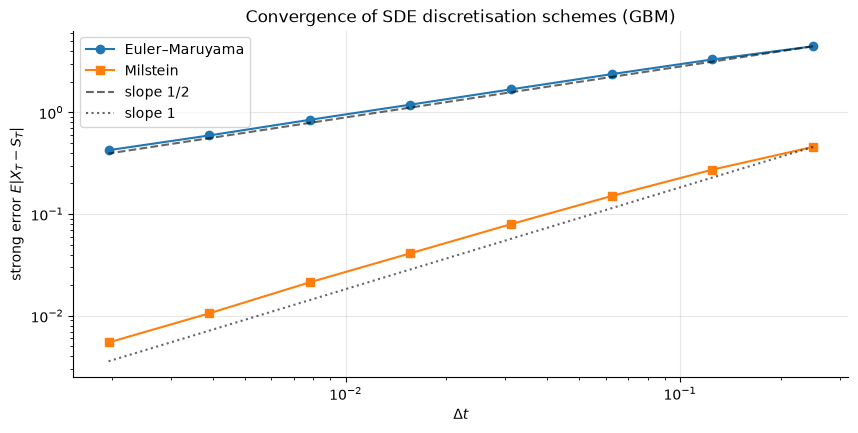

Fitted slopes: Euler = 0.49 (theory 0.5), Milstein = 0.92 (theory 1.0)


In [17]:
def strong_errors(n_steps, n_paths=20_000, S0=100.0, mu=0.05, sigma=0.4, T=1.0):
    dt = T / n_steps
    dW = rng.normal(0, np.sqrt(dt), size=(n_paths, n_steps))
    S_eu = np.full(n_paths, S0)
    S_mi = np.full(n_paths, S0)
    for k in range(n_steps):
        S_eu = S_eu + mu * S_eu * dt + sigma * S_eu * dW[:, k]
        S_mi = S_mi + mu * S_mi * dt + sigma * S_mi * dW[:, k] \
               + 0.5 * sigma**2 * S_mi * (dW[:, k]**2 - dt)
    S_ex = S0 * np.exp((mu - 0.5 * sigma**2) * T + sigma * dW.sum(axis=1))
    return np.mean(np.abs(S_eu - S_ex)), np.mean(np.abs(S_mi - S_ex))

steps = np.array([4, 8, 16, 32, 64, 128, 256, 512])
errs = np.array([strong_errors(n) for n in steps])
dts = 1.0 / steps

plt.loglog(dts, errs[:, 0], "o-", label="Euler–Maruyama")
plt.loglog(dts, errs[:, 1], "s-", label="Milstein")
plt.loglog(dts, errs[0, 0] * (dts / dts[0])**0.5, "k--", alpha=0.6, label=r"slope 1/2")
plt.loglog(dts, errs[0, 1] * (dts / dts[0])**1.0, "k:", alpha=0.6, label=r"slope 1")
plt.xlabel(r"$\Delta t$"); plt.ylabel(r"strong error $E|X_T - S_T|$")
plt.title("Convergence of SDE discretisation schemes (GBM)")
plt.legend()
plt.show()

slopes = np.polyfit(np.log(dts), np.log(errs), 1)[0]
print(f"Fitted slopes: Euler = {slopes[0]:.2f} (theory 0.5), Milstein = {slopes[1]:.2f} (theory 1.0)")

Notes to self:
* If there's an exact solution (GBM, OU/Vasicek), just simulate that. Zero discretisation error.
* For pricing what matters is the weak error $|\mathbb E f(X^{\text{scheme}}) - \mathbb E f(X)|$, which for Euler is usually $O(\Delta t)$, better than the strong rate.
* Simulating $\ln S$ instead of $S$ keeps prices positive. Euler on $S$ directly can go negative with big steps.

## 8. Estimating $\mu$ and $\sigma$ from data

This was the most surprising part for me.

Say prices really follow GBM and I observe log-returns $r_i = \ln(S_{t_{i+1}}/S_{t_i})$ every $\Delta t$ over a total time $T$. Each $r_i \sim \mathcal N\big((\mu-\tfrac12\sigma^2)\Delta t,\ \sigma^2\Delta t\big)$, independent.

* Volatility: $\hat\sigma^2 = \frac{1}{(n-1)\Delta t}\sum_i (r_i - \bar r)^2$. Relative standard error $\approx 1/\sqrt{2n}$, so it improves with the number of observations. Sampling more often helps.
* Drift: $\hat\mu = \frac{1}{T}\ln(S_T/S_0) + \tfrac12\hat\sigma^2$. This only depends on the endpoints. Standard error is $\sigma/\sqrt{T}$, so it only improves with the length of the history, no matter how often you sample.

With $\sigma = 20\%$, getting $\mu$ to $\pm 2\%$ needs $T = (0.2/0.02)^2 = 100$ years of data. Markets change long before that.

In [18]:
def estimate(mu, sigma, T_years, obs_per_year, n_trials=500):
    n = int(T_years * obs_per_year)
    dt = 1.0 / obs_per_year
    mu_hat = np.empty(n_trials); sig_hat = np.empty(n_trials)
    for i in range(n_trials):
        r = rng.normal((mu - 0.5 * sigma**2) * dt, sigma * np.sqrt(dt), size=n)
        sig_hat[i] = r.std(ddof=1) / np.sqrt(dt)
        mu_hat[i] = r.sum() / T_years + 0.5 * sig_hat[i]**2
    return mu_hat, sig_hat

mu_true, sig_true = 0.08, 0.20
print(f"True mu = {mu_true:.0%}, true sigma = {sig_true:.0%}\n")
print(f"{'history':>8} | {'sampling':>9} | {'std error of mu_hat':>19} | {'std error of sigma_hat':>22}")
print("-" * 68)
for T_years in [1, 10]:
    for label, freq in [("weekly", 52), ("daily", 252), ("5-min", 252 * 78)]:
        m, s = estimate(mu_true, sig_true, T_years, freq, n_trials=200 if freq > 1000 else 500)
        print(f"{T_years:>6} y | {label:>9} | {m.std():>19.2%} | {s.std():>22.3%}")
print(f"\nTheory for mu: sigma/sqrt(T) = {sig_true:.0%}/sqrt(T)  ->  1y: {sig_true:.1%}, 10y: {sig_true/np.sqrt(10):.1%}")

True mu = 8%, true sigma = 20%

 history |  sampling | std error of mu_hat | std error of sigma_hat
--------------------------------------------------------------------
     1 y |    weekly |              20.58% |                 1.994%
     1 y |     daily |              19.21% |                 0.894%
     1 y |     5-min |              20.82% |                 0.101%
    10 y |    weekly |               6.35% |                 0.660%
    10 y |     daily |               6.63% |                 0.275%
    10 y |     5-min |               6.38% |                 0.031%

Theory for mu: sigma/sqrt(T) = 20%/sqrt(T)  ->  1y: 20.0%, 10y: 6.3%


Going from weekly to 5-minute data cuts the vol error by about 20x but does nothing for the drift. Even 10 years of data leaves roughly ±6% uncertainty on an 8% expected return.

Consequences:
* Option pricing (next section) only needs $\sigma$, which is measurable. Part of why derivatives pricing is fairly well understood.
* Predicting returns (alpha research) is fighting exactly this signal-to-noise problem. People look for lots of small, weak predictors, test across many assets and horizons, and worry a lot about overfitting. Coming from particle physics this feels familiar: it's basically the same problem as systematics and the look-elsewhere effect.

## 9. Risk-neutral pricing and Black-Scholes

### 9.1 Hedging removes $\mu$
A European call pays $(S_T - K)^+$ at $T$. Let $V(t, S)$ be its price, and form the portfolio long one option, short $\Delta$ shares: $\Pi = V - \Delta S$. Itô gives
$$dV = \Big(V_t + \mu S V_S + \tfrac12\sigma^2 S^2 V_{SS}\Big)dt + \sigma S V_S\,dW,$$
so $d\Pi = dV - \Delta\, dS = \big(V_t + \mu S V_S + \tfrac12\sigma^2S^2V_{SS} - \Delta\mu S\big)dt + \sigma S\,(V_S - \Delta)\,dW$.

Pick $\Delta = V_S$ (delta hedging). The $dW$ term drops out and so do all the $\mu$ terms. A riskless portfolio has to earn the risk-free rate, $d\Pi = r\Pi\,dt$, which gives the Black-Scholes PDE:
$$V_t + rSV_S + \tfrac12\sigma^2S^2V_{SS} - rV = 0, \qquad V(T,S) = (S-K)^+ .$$
No $\mu$. Two people who completely disagree about the stock's expected return still have to agree on the option price, since both can replicate it.

### 9.2 Probabilistic version
By Feynman-Kac the PDE solution is an expectation:
$$V(0, S_0) = e^{-rT}\,\mathbb E^{\mathbb Q}\big[(S_T - K)^+\big], \qquad \text{where under } \mathbb Q:\ \frac{dS_t}{S_t} = r\,dt + \sigma\,dW^{\mathbb Q}_t .$$
$\mathbb Q$ is the risk-neutral measure: same vol, but everything drifts at $r$. Girsanov's theorem is what makes this rigorous: changing measure shifts the drift of a BM ($W^{\mathbb Q}_t = W_t + \frac{\mu - r}{\sigma}t$) without touching the vol. $\frac{\mu-r}{\sigma}$ is the market price of risk (Sharpe ratio).

Doing the integral gives the Black-Scholes formula:
$$C = S_0\,N(d_1) - K e^{-rT} N(d_2), \qquad d_{1,2} = \frac{\ln(S_0/K) + (r \pm \tfrac12\sigma^2)T}{\sigma\sqrt T},$$
with delta $\partial C/\partial S = N(d_1)$ and gamma $\partial^2 C/\partial S^2 = \frac{N'(d_1)}{S\sigma\sqrt T}$.

In [19]:
def bs_call(S, K, T, r, sigma):
    S = np.asarray(S, dtype=float)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S * stats.norm.cdf(d1) - K * np.exp(-r * T) * stats.norm.cdf(d2)

def bs_delta(S, K, T, r, sigma):
    d1 = (np.log(np.asarray(S) / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    return stats.norm.cdf(d1)

def bs_gamma(S, K, T, r, sigma):
    S = np.asarray(S, dtype=float)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    return stats.norm.pdf(d1) / (S * sigma * np.sqrt(T))

S0, K, T, r, sigma = 100.0, 105.0, 1.0, 0.04, 0.20
print(f"Black-Scholes call price = {bs_call(S0, K, T, r, sigma):.4f}")
print(f"Delta = {bs_delta(S0, K, T, r, sigma):.4f}, Gamma = {bs_gamma(S0, K, T, r, sigma):.5f}")

# Sanity check: put-call parity  C - P = S0 - K e^{-rT}
put_mc = np.exp(-r * T) * np.mean(np.maximum(
    K - S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * rng.standard_normal(2_000_000)), 0))
print(f"Put-call parity: C - P = {bs_call(S0, K, T, r, sigma) - put_mc:.3f}  vs  S0 - K e^(-rT) = {S0 - K * np.exp(-r * T):.3f}")

Black-Scholes call price = 7.5670
Delta = 0.5223, Gamma = 0.01992
Put-call parity: C - P = -0.886  vs  S0 - K e^(-rT) = -0.883


### 9.3 Checking that $\mu$ doesn't matter
The naive approach would be: take the expected payoff under the real-world drift $\mu$ and discount at $r$. That gives a different price for every $\mu$, and all of them except $\mu = r$ can be arbitraged with the delta hedge above.

In [20]:
Z = rng.standard_normal(1_000_000)
print(f"{'drift used':>12} | {'discounted E[payoff]':>20}")
for drift in [0.00, 0.04, 0.08, 0.15]:
    ST = S0 * np.exp((drift - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    tag = "  <- risk-neutral (= Black-Scholes)" if drift == r else ""
    print(f"{drift:>12.0%} | {np.exp(-r * T) * np.maximum(ST - K, 0).mean():>20.4f}{tag}")

  drift used | discounted E[payoff]
          0% |               5.6796
          4% |               7.5754  <- risk-neutral (= Black-Scholes)
          8% |               9.8702
         15% |              14.9018


## 10. Monte Carlo pricing

When there's no formula (path-dependent or multi-asset payoffs) you simulate:
1. Simulate $N$ paths under $\mathbb Q$.
2. Average the discounted payoffs, $\hat V = e^{-rT}\frac1N\sum_i \text{payoff}_i$.
3. Report a confidence interval, $\hat V \pm 1.96\,\hat s/\sqrt N$.

Error goes like $1/\sqrt N$, so 100x more paths for 10x more accuracy. That's slow, hence variance reduction.

Antithetic variates: for every $Z$ also use $-Z$. The two payoffs are negatively correlated so their average has lower variance, basically for free.

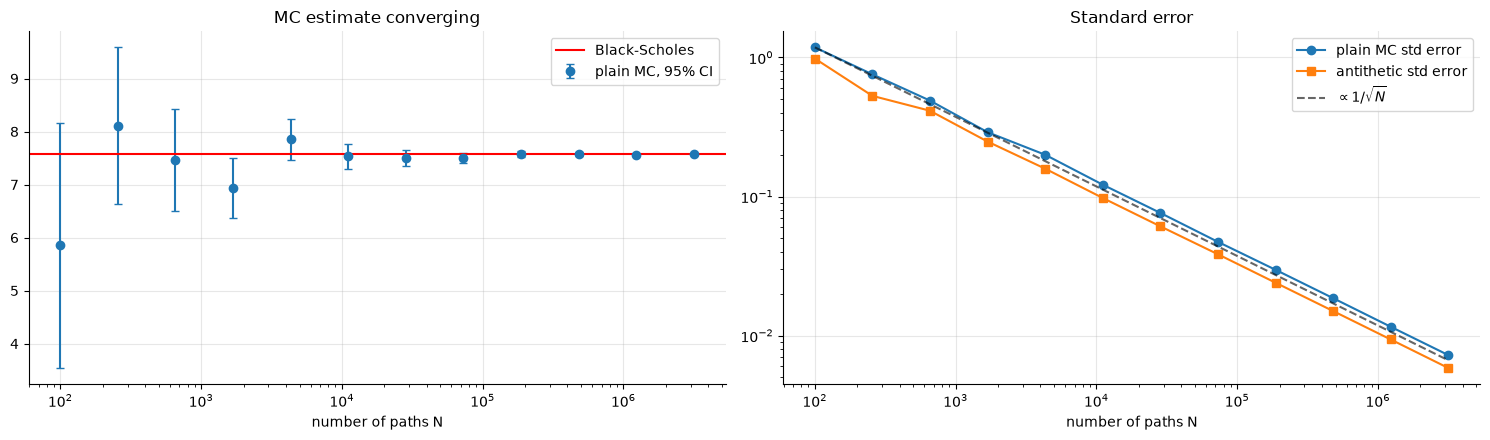

Variance reduction from antithetics: ~1.5x fewer paths for same accuracy


In [21]:
def mc_call(N, antithetic=False):
    if antithetic:
        Zh = rng.standard_normal(N // 2)
        Z = np.concatenate([Zh, -Zh])
    else:
        Z = rng.standard_normal(N)
    ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    pay = np.exp(-r * T) * np.maximum(ST - K, 0)
    if antithetic:   # standard error must use the PAIR averages (they are the iid samples)
        pairs = 0.5 * (pay[: N // 2] + pay[N // 2:])
        return pairs.mean(), pairs.std(ddof=1) / np.sqrt(N // 2)
    return pay.mean(), pay.std(ddof=1) / np.sqrt(N)

exact = bs_call(S0, K, T, r, sigma)
Ns = np.logspace(2, 6.5, 12).astype(int) // 2 * 2
plain = np.array([mc_call(N) for N in Ns])
anti = np.array([mc_call(N, antithetic=True) for N in Ns])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].errorbar(Ns, plain[:, 0], yerr=1.96 * plain[:, 1], fmt="o", capsize=3, label="plain MC, 95% CI")
axes[0].axhline(exact, color="r", label="Black-Scholes")
axes[0].set_xscale("log"); axes[0].set_xlabel("number of paths N"); axes[0].set_title("MC estimate converging")
axes[0].legend()
axes[1].loglog(Ns, plain[:, 1], "o-", label="plain MC std error")
axes[1].loglog(Ns, anti[:, 1], "s-", label="antithetic std error")
axes[1].loglog(Ns, plain[0, 1] * np.sqrt(Ns[0] / Ns), "k--", alpha=0.6, label=r"$\propto 1/\sqrt{N}$")
axes[1].set_xlabel("number of paths N"); axes[1].set_title("Standard error"); axes[1].legend()
plt.tight_layout()
plt.show()
print(f"Variance reduction from antithetics: ~{(plain[:, 1] / anti[:, 1]).mean()**2:.1f}x fewer paths for same accuracy")

### 10.1 Path-dependent example: Asian option
An arithmetic-average Asian call pays $\big(\bar S - K\big)^+$ where $\bar S$ is the average price over the option's life. No closed form, so MC. Averaging smooths things out, so it should come out cheaper than the vanilla call.

Control variates: the geometric-average Asian does have a closed form and is very highly correlated with the arithmetic one. So simulate the difference and add the known value back.

In [22]:
def geometric_asian_exact(S0, K, T, r, sigma, n):
    # closed form for discrete geometric Asian call, n fixings at T/n, 2T/n, ..., T
    mu_G = np.log(S0) + (r - 0.5 * sigma**2) * T * (n + 1) / (2 * n)
    var_G = sigma**2 * T * (n + 1) * (2 * n + 1) / (6 * n**2)
    d1 = (mu_G - np.log(K) + var_G) / np.sqrt(var_G)
    d2 = d1 - np.sqrt(var_G)
    return np.exp(-r * T) * (np.exp(mu_G + 0.5 * var_G) * stats.norm.cdf(d1) - K * stats.norm.cdf(d2))

n_fix, N = 52, 200_000
dt = T / n_fix
Z = rng.standard_normal((N, n_fix))
paths = S0 * np.exp(np.cumsum((r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z, axis=1))
disc = np.exp(-r * T)
arith = disc * np.maximum(paths.mean(axis=1) - K, 0)
geo = disc * np.maximum(np.exp(np.log(paths).mean(axis=1)) - K, 0)
geo_exact = geometric_asian_exact(S0, K, T, r, sigma, n_fix)

b = np.cov(arith, geo)[0, 1] / geo.var()           # optimal control-variate coefficient
cv = arith - b * (geo - geo_exact)

print(f"Vanilla BS call                    = {bs_call(S0, K, T, r, sigma):.4f}")
print(f"Asian (plain MC)                   = {arith.mean():.4f} +- {1.96 * arith.std() / np.sqrt(N):.4f}")
print(f"Asian (control variate)            = {cv.mean():.4f} +- {1.96 * cv.std() / np.sqrt(N):.4f}")
print(f"Correlation(arith, geo) = {np.corrcoef(arith, geo)[0, 1]:.4f} -> "
      f"variance reduced {arith.var() / cv.var():.0f}x")

Vanilla BS call                    = 7.5670
Asian (plain MC)                   = 3.4176 +- 0.0281
Asian (control variate)            = 3.4033 +- 0.0009
Correlation(arith, geo) = 0.9995 -> variance reduced 970x


## 11. Delta hedging in practice

Black-Scholes assumes continuous rebalancing. In practice you rebalance at discrete times, so the replication isn't perfect. Simulating what a desk would do:

1. Sell a call at the BS price.
2. Buy $\Delta = N(d_1)$ shares, financed with cash (earning/paying $r$).
3. At each rebalance date recompute $\Delta$ and trade the difference.
4. At expiry pay out the option and record the P&L.

The stock is simulated with the real-world drift $\mu = 12\%$, not $r$. If the theory is right the P&L should still be centred around zero.

rebalances |  mean P&L |  std P&L | std x sqrt(n)
         4 |   -0.1922 |   3.5427 |         7.085
        12 |   -0.0512 |   2.0485 |         7.096
        52 |   -0.0139 |   0.9984 |         7.199
       252 |   -0.0041 |   0.4574 |         7.262
      1008 |   -0.0001 |   0.2321 |         7.370


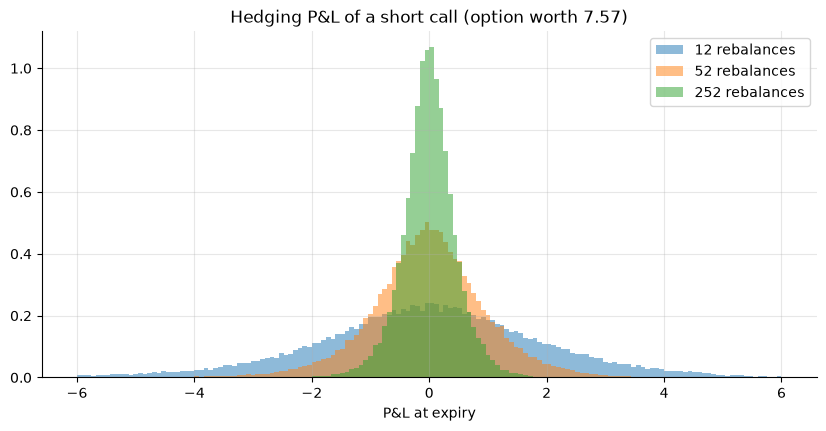

In [23]:
def delta_hedge_pnl(n_paths, n_rebal, S0, K, T, r, sigma_real, sigma_hedge, mu):
    # sell a call priced at sigma_hedge, delta hedge it n_rebal times, return final P&L
    dt = T / n_rebal
    S = np.full(n_paths, S0)
    delta = bs_delta(S, K, T, r, sigma_hedge)
    cash = bs_call(S0, K, T, r, sigma_hedge) - delta * S    # premium in, buy delta shares
    for k in range(1, n_rebal + 1):
        Z = rng.standard_normal(n_paths)
        S = S * np.exp((mu - 0.5 * sigma_real**2) * dt + sigma_real * np.sqrt(dt) * Z)
        cash = cash * np.exp(r * dt)
        if k < n_rebal:
            new_delta = bs_delta(S, K, T - k * dt, r, sigma_hedge)
            cash -= (new_delta - delta) * S
            delta = new_delta
    return cash + delta * S - np.maximum(S - K, 0)

mu_real = 0.12
fig, ax = plt.subplots()
print(f"{'rebalances':>10} | {'mean P&L':>9} | {'std P&L':>8} | {'std x sqrt(n)':>13}")
for n_rebal in [4, 12, 52, 252, 1008]:
    pnl = delta_hedge_pnl(50_000, n_rebal, S0, K, T, r, sigma, sigma, mu_real)
    print(f"{n_rebal:>10} | {pnl.mean():>9.4f} | {pnl.std():>8.4f} | {pnl.std() * np.sqrt(n_rebal):>13.3f}")
    if n_rebal in (12, 52, 252):
        ax.hist(pnl, bins=150, range=(-6, 6), density=True, alpha=0.5, label=f"{n_rebal} rebalances")
ax.set_title(f"Hedging P&L of a short call (option worth {bs_call(S0, K, T, r, sigma):.2f})")
ax.set_xlabel("P&L at expiry"); ax.legend()
plt.show()

What I see:
* Mean P&L ≈ 0 even though the stock drifts at 12%, so $\mu$ really drops out for a hedged position.
* Hedging error shrinks like $1/\sqrt{n}$ (last column is roughly constant). More rebalancing means more transaction costs, so in practice there's a trade-off.

### 11.1 Hedging with the wrong vol
Suppose I sell the option at 25% implied vol but the stock only realises 20%, and I delta hedge using the implied vol. The standard result for the P&L is
$$\text{P\&L} \approx \tfrac12\int_0^T e^{r(T-t)}\,\Gamma_t S_t^2\,\big(\sigma_{\text{implied}}^2 - \sigma_{\text{realized}}^2\big)\,dt.$$
So a delta-hedged short option is a bet that realised vol ends up below implied. Market makers think about options this way: not direction, but vol. It's also the basis of "volatility risk premium" strategies.

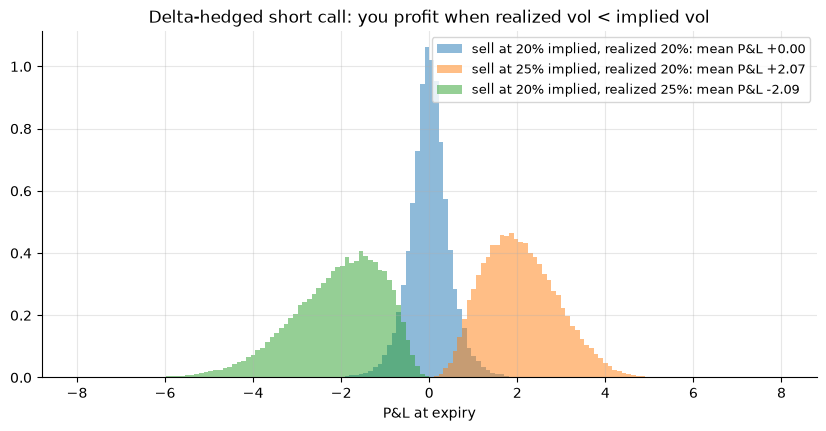

Price difference between 25% and 20% vol: 1.99  (compare with the mean P&L above)


In [24]:
fig, ax = plt.subplots()
for sig_impl, sig_real in [(0.20, 0.20), (0.25, 0.20), (0.20, 0.25)]:
    pnl = delta_hedge_pnl(50_000, 252, S0, K, T, r, sig_real, sig_impl, mu_real)
    lbl = f"sell at {sig_impl:.0%} implied, realized {sig_real:.0%}: mean P&L {pnl.mean():+.2f}"
    ax.hist(pnl, bins=150, range=(-8, 8), density=True, alpha=0.5, label=lbl)
ax.set_title("Delta-hedged short call: you profit when realized vol < implied vol")
ax.set_xlabel("P&L at expiry"); ax.legend(fontsize=9)
plt.show()

vega_diff = bs_call(S0, K, T, r, 0.25) - bs_call(S0, K, T, r, 0.20)
print(f"Price difference between 25% and 20% vol: {vega_diff:.2f}  (compare with the mean P&L above)")

## 12. Reflection principle and first-passage times

### 12.1 Running maximum
Let $M_T = \max_{0\le s\le T} W_s$. Reflection principle: for $a > 0$,
$$\mathbb P(M_T \ge a) = 2\,\mathbb P(W_T \ge a) = 2\big(1 - N(a/\sqrt T)\big).$$
Reason: any path that hits $a$ and ends below it can be reflected about $a$ after the first hitting time, giving a path that ends above $a$. That's a one-to-one, probability-preserving map, so paths that touched $a$ split 50/50 between ending above and below.

Used for barrier options (knock-in/knock-out), whose closed-form prices come from this.

One thing to watch out for: simulating on a discrete grid misses crossings that happen between grid points, so you underestimate the hitting probability. That's a real source of mispricing for barriers. Fixes are the Broadie-Glasserman-Kou continuity correction or a Brownian-bridge crossing probability.

In [25]:
a, T = 1.0, 1.0
exact_p = 2 * (1 - stats.norm.cdf(a / np.sqrt(T)))
print(f"Exact P(max W >= {a}) on [0, {T}] = {exact_p:.4f}\n")
print(f"{'grid steps':>10} | {'simulated P':>11} | {'bias':>8}")
for n_steps in [10, 50, 250, 1000, 5000]:
    _, Wb = brownian_paths(20_000, n_steps, T)
    p = np.mean(Wb.max(axis=1) >= a)
    print(f"{n_steps:>10} | {p:>11.4f} | {p - exact_p:>+8.4f}")

Exact P(max W >= 1.0) on [0, 1.0] = 0.3173

grid steps | simulated P |     bias
        10 |      0.2433 |  -0.0740
        50 |      0.2780 |  -0.0393
       250 |      0.2959 |  -0.0214
      1000 |      0.3101 |  -0.0072
      5000 |      0.3142 |  -0.0031


### 12.2 Gambler's ruin
Start $W$ at 0 and stop when it first hits $+a$ or $-b$. Since $W_t$ and $W_t^2 - t$ are martingales, optional stopping gives:
* $\mathbb E[W_\tau] = 0 \Rightarrow a\,p - b\,(1-p) = 0 \Rightarrow \mathbb P(\text{hit } +a \text{ first}) = \frac{b}{a+b}$
* $\mathbb E[W_\tau^2 - \tau] = 0 \Rightarrow \mathbb E[\tau] = a^2p + b^2(1-p) = ab$

Same logic gives the probability that a strategy hits its profit target before its stop-loss.

In [26]:
def gamblers_ruin(a, b, n_paths=20_000, dt=1e-3):
    x = np.zeros(n_paths)
    tau = np.zeros(n_paths)
    alive = np.ones(n_paths, dtype=bool)
    while alive.any():
        idx_alive = np.flatnonzero(alive)
        x[idx_alive] += rng.normal(0, np.sqrt(dt), size=idx_alive.size)
        tau[idx_alive] += dt
        alive[idx_alive] = (x[idx_alive] < a) & (x[idx_alive] > -b)
    return np.mean(x >= a), tau.mean()

a, b = 1.0, 2.0
p_up, mean_tau = gamblers_ruin(a, b)
print(f"P(hit +{a} before -{b}) = {p_up:.4f}   theory b/(a+b) = {b / (a + b):.4f}")
print(f"E[stopping time]       = {mean_tau:.4f}   theory a*b     = {a * b:.4f}")

P(hit +1.0 before -2.0) = 0.6644   theory b/(a+b) = 0.6667
E[stopping time]       = 2.0557   theory a*b     = 2.0000


## 13. Mean reversion: Ornstein-Uhlenbeck and Vasicek

Stock prices wander off, but things like interest rates, volatility, and spreads between related assets tend to get pulled back to some long-run level. The OU process:
$$dr_t = \kappa(\theta - r_t)\,dt + \sigma\,dW_t .$$
* $\theta$ = long-run mean, $\kappa$ = speed of mean reversion (half-life $\ln 2/\kappa$), $\sigma$ = vol.
* The drift always points back toward $\theta$, and harder the further away you are.

Exact solution (apply Itô to $e^{\kappa t} r_t$):
$$r_{t+\Delta} = \theta + (r_t - \theta)e^{-\kappa\Delta} + \sigma\sqrt{\frac{1 - e^{-2\kappa\Delta}}{2\kappa}}\;Z, \qquad Z\sim\mathcal N(0,1).$$
Stationary distribution: $\mathcal N\big(\theta,\ \sigma^2/(2\kappa)\big)$.

As a short-rate model this is Vasicek (1977). Where it shows up:
* Rates: bond and bond-option pricing.
* Stat arb: the spread between two cointegrated stocks is often modelled as OU, and you trade when it's far from $\theta$ (pairs trading, e.g. Avellaneda-Lee).

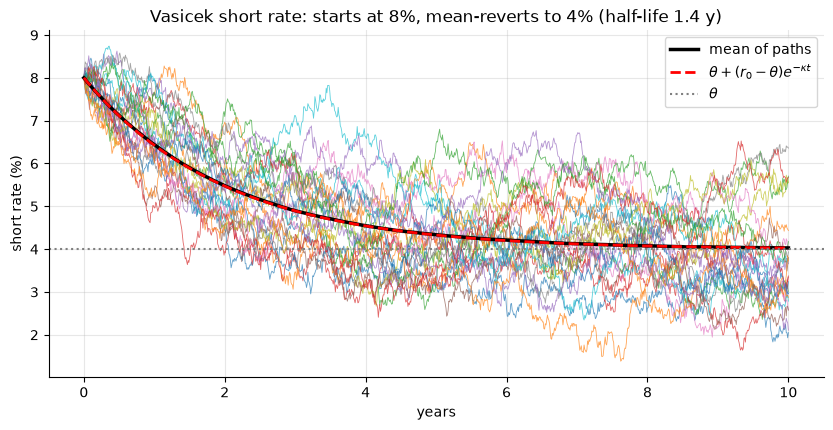

Long-run std: simulated 0.9876%, theory sigma/sqrt(2 kappa) = 1.0000%
Fraction of paths with negative rates at year 10: 0.000%  (Vasicek allows r < 0)


In [27]:
def simulate_ou(r0, kappa, theta, sigma, T, n_steps, n_paths):
    dt = T / n_steps
    decay = np.exp(-kappa * dt)
    sd = sigma * np.sqrt((1 - np.exp(-2 * kappa * dt)) / (2 * kappa))
    r_ = np.empty((n_paths, n_steps + 1))
    r_[:, 0] = r0
    for k in range(n_steps):
        r_[:, k + 1] = theta + (r_[:, k] - theta) * decay + sd * rng.standard_normal(n_paths)
    return np.linspace(0, T, n_steps + 1), r_

kappa, theta, sig_r, r0 = 0.5, 0.04, 0.01, 0.08
tt, rates = simulate_ou(r0, kappa, theta, sig_r, T=10, n_steps=1000, n_paths=20_000)

plt.plot(tt, rates[:25].T * 100, lw=0.6, alpha=0.7)
plt.plot(tt, rates.mean(axis=0) * 100, "k", lw=2.5, label="mean of paths")
plt.plot(tt, (theta + (r0 - theta) * np.exp(-kappa * tt)) * 100, "r--", lw=2,
         label=r"$\theta + (r_0-\theta)e^{-\kappa t}$")
plt.axhline(theta * 100, color="gray", ls=":", label=r"$\theta$")
plt.ylabel("short rate (%)"); plt.xlabel("years")
plt.title(f"Vasicek short rate: starts at {r0:.0%}, mean-reverts to {theta:.0%} (half-life {np.log(2)/kappa:.1f} y)")
plt.legend()
plt.show()

print(f"Long-run std: simulated {rates[:, -1].std():.4%}, theory sigma/sqrt(2 kappa) = {sig_r / np.sqrt(2 * kappa):.4%}")
print(f"Fraction of paths with negative rates at year 10: {np.mean(rates[:, -1] < 0):.3%}  (Vasicek allows r < 0)")

### 13.1 Zero-coupon bond
A zero-coupon bond paying $\$1$ at $T$ is worth
$$P(0, T) = \mathbb E^{\mathbb Q}\Big[\exp\Big(-\int_0^T r_s\,ds\Big)\Big],$$
the risk-neutral expectation of the discount factor along each rate path. Vasicek has a closed form:
$$P(0,T) = A(T)\,e^{-B(T)\,r_0}, \quad B(T) = \frac{1 - e^{-\kappa T}}{\kappa}, \quad A(T) = \exp\!\Big[\Big(\theta - \frac{\sigma^2}{2\kappa^2}\Big)\big(B(T) - T\big) - \frac{\sigma^2 B(T)^2}{4\kappa}\Big].$$
(Parameters here are taken to be the risk-neutral ones.) Comparing with MC and plotting the yield curve $y(T) = -\ln P(0,T)/T$:

  T | closed form | Monte Carlo | 95% CI half-width
  1 |     0.93103 |     0.93103 |           0.00006
  2 |     0.87765 |     0.87777 |           0.00014
  5 |     0.76112 |     0.76131 |           0.00032
 10 |     0.61999 |     0.62008 |           0.00046


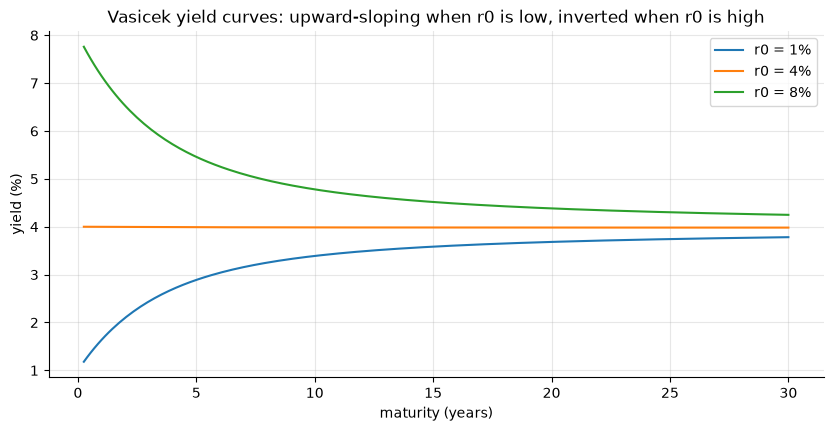

In [28]:
def vasicek_zcb(r0, kappa, theta, sigma, T):
    B = (1 - np.exp(-kappa * T)) / kappa
    A = np.exp((theta - sigma**2 / (2 * kappa**2)) * (B - T) - sigma**2 * B**2 / (4 * kappa))
    return A * np.exp(-B * r0)

maturities = np.array([1, 2, 5, 10])
print(f"{'T':>3} | {'closed form':>11} | {'Monte Carlo':>11} | {'95% CI half-width':>17}")
for Tm in maturities:
    tt_, rr = simulate_ou(r0, kappa, theta, sig_r, T=Tm, n_steps=int(Tm * 100), n_paths=20_000)
    dt_ = tt_[1] - tt_[0]
    integral = dt_ * (rr[:, 1:-1].sum(axis=1) + 0.5 * (rr[:, 0] + rr[:, -1]))   # trapezoid rule
    disc = np.exp(-integral)
    print(f"{Tm:>3} | {vasicek_zcb(r0, kappa, theta, sig_r, Tm):>11.5f} | {disc.mean():>11.5f} | "
          f"{1.96 * disc.std() / np.sqrt(len(disc)):>17.5f}")

T_grid = np.linspace(0.25, 30, 200)
for r_start in [0.01, 0.04, 0.08]:
    y = -np.log(vasicek_zcb(r_start, kappa, theta, sig_r, T_grid)) / T_grid
    plt.plot(T_grid, y * 100, label=f"r0 = {r_start:.0%}")
plt.xlabel("maturity (years)"); plt.ylabel("yield (%)")
plt.title("Vasicek yield curves: upward-sloping when r0 is low, inverted when r0 is high")
plt.legend()
plt.show()

Duration: $\partial \ln P/\partial r_0 = -B(T) = -(1 - e^{-\kappa T})/\kappa$, which saturates at $1/\kappa$ for long maturities. Because rates mean-revert, a shock to today's short rate barely moves 30-year yields. This is Vasicek's version of DV01, and it's why hedging long bonds with short-rate instruments is tricky (key-rate durations, PCA hedges, etc.).

## 14. Where Brownian motion fails

GBM is a starting point, not reality. Real returns show:

| Stylised fact | GBM | Reality | Better models |
|---|---|---|---|
| Fat tails | Gaussian daily returns (excess kurtosis 0) | crashes much more common than Gaussian | Merton jump-diffusion, Lévy processes, Student-t |
| Vol clustering | constant $\sigma$ | calm and turbulent periods cluster | GARCH, Heston, rough vol |
| Leverage effect | none | vol goes up when prices fall | Heston with $\rho<0$, SABR |
| Vol smile | flat implied vol | implied vol depends on strike and maturity | local vol (Dupire), stoch vol, jumps |
| Microstructure | continuous prices | tick grid, discrete trades, bid-ask bounce | Hawkes processes, order-book models |

Below I compare GBM returns with a toy GARCH(1,1), $\sigma_t^2 = \omega + \alpha r_{t-1}^2 + \beta\sigma_{t-1}^2$, which gives fat tails and clustering. Real data looks a lot more like the right column.

TODO: pull real daily index returns (e.g. `yfinance`) and make the same plots, compute excess kurtosis and the ACF of $|r_t|$.

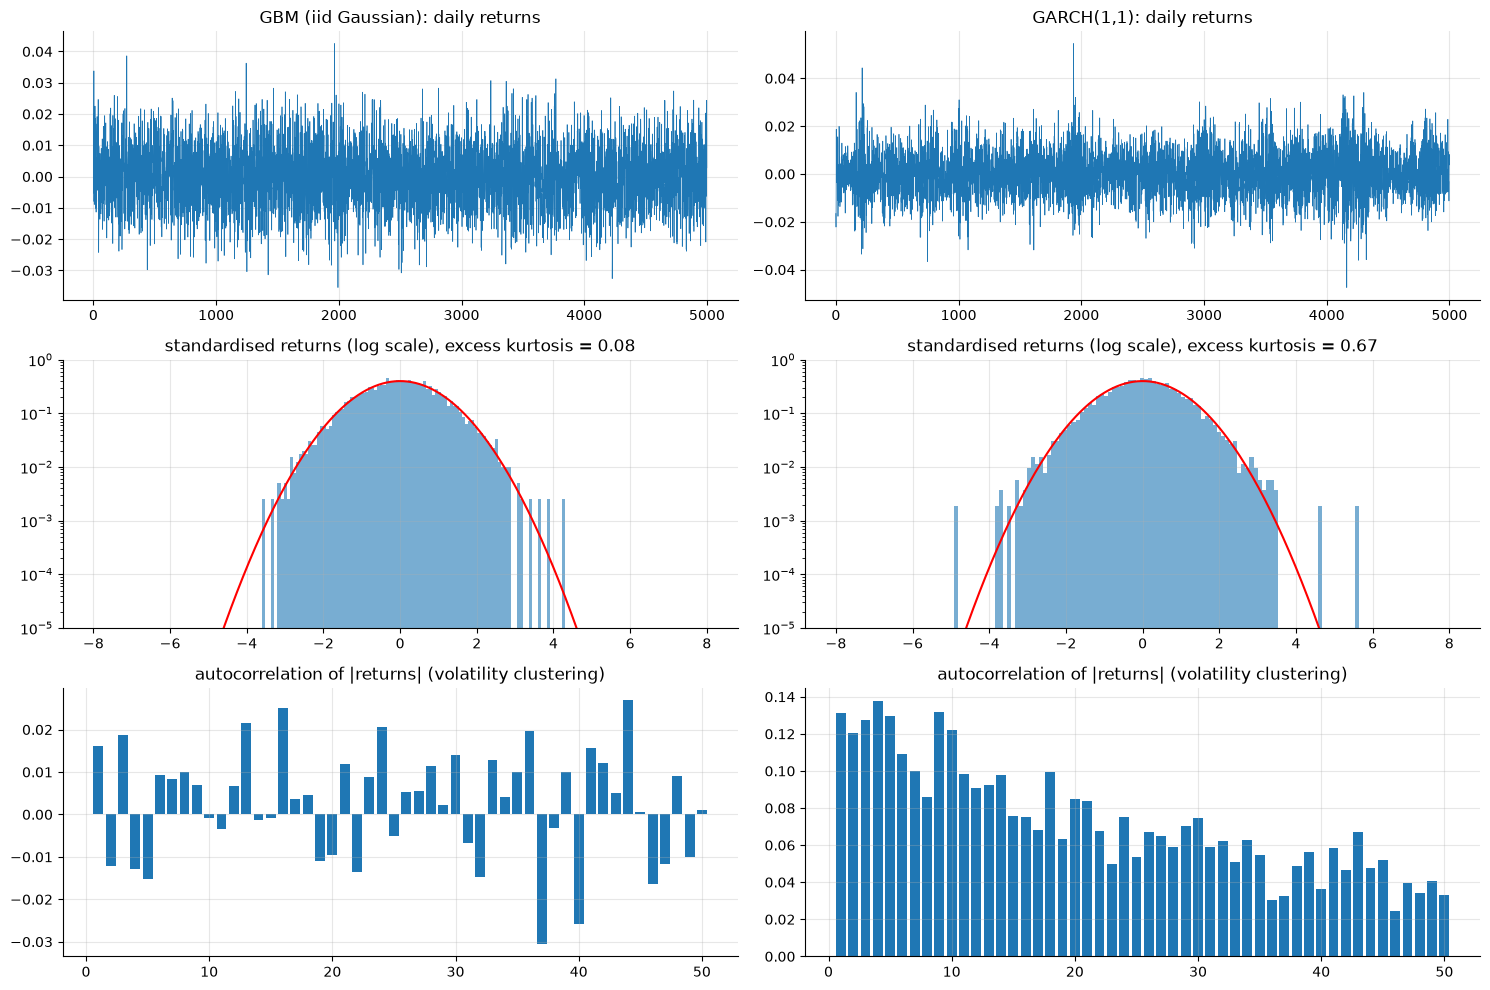

In [29]:
n_days = 5_000
sigma_daily = 0.01
gbm_r = sigma_daily * rng.standard_normal(n_days)

omega, alpha, beta = 2e-6, 0.09, 0.89          # alpha+beta < 1 -> stationary
uncond_var = omega / (1 - alpha - beta)
garch_r = np.empty(n_days); var_t = uncond_var
for i in range(n_days):
    garch_r[i] = np.sqrt(var_t) * rng.standard_normal()
    var_t = omega + alpha * garch_r[i]**2 + beta * var_t

def acf(x, lags):
    x = x - x.mean()
    return np.array([np.corrcoef(x[:-L], x[L:])[0, 1] for L in lags])

lags = np.arange(1, 51)
fig, axes = plt.subplots(3, 2, figsize=(15, 10))
for col, (name, ret) in enumerate([("GBM (iid Gaussian)", gbm_r), ("GARCH(1,1)", garch_r)]):
    axes[0, col].plot(ret, lw=0.5); axes[0, col].set_title(f"{name}: daily returns")
    z = (ret - ret.mean()) / ret.std()
    axes[1, col].hist(z, bins=100, density=True, alpha=0.6, log=True)
    xs = np.linspace(-8, 8, 300)
    axes[1, col].plot(xs, stats.norm.pdf(xs), "r"); axes[1, col].set_ylim(1e-5, 1)
    axes[1, col].set_title(f"standardised returns (log scale), excess kurtosis = {stats.kurtosis(ret):.2f}")
    axes[2, col].bar(lags, acf(np.abs(ret), lags))
    axes[2, col].set_title("autocorrelation of |returns| (volatility clustering)")
plt.tight_layout()
plt.show()

## 15. Interview-style problems

Collected these while preparing. Solutions are hidden, and the MC cell after checks them.

**Q1.** $\mathbb P(W_1 > 0 \text{ and } W_2 > 0)$?
<details><summary>solution</summary>

$W_1 = X$, $W_2 = X + Y$ with $X, Y$ iid $\mathcal N(0,1)$. Need $\mathbb P(X>0, X+Y>0)$. $(X, Y)$ is rotationally symmetric so the probability is the angle of the region over $2\pi$. $\{x>0\}\cap\{x+y>0\}$ is a wedge of angle $\pi/2 + \pi/4 = 3\pi/4$, so the answer is $3/8$.
</details>

**Q2.** $\mathbb E[W_t^4]$?
<details><summary>solution</summary>

$W_t = \sqrt t Z$ and $\mathbb E[Z^4] = 3$, so $3t^2$. (Or with Itô: $d(W^4) = 4W^3dW + 6W^2dt$, take expectations, $\frac{d}{dt}\mathbb E[W^4] = 6t$.)
</details>

**Q3.** $\mathrm{Var}\big(\int_0^1 W_t\,dt\big)$?
<details><summary>solution</summary>

$\int_0^1\!\!\int_0^1 \min(s,t)\,ds\,dt = 2\int_0^1\!\int_0^t s\,ds\,dt = 2\int_0^1 \tfrac{t^2}{2}dt = 1/3$.
</details>

**Q4.** Is $W_t^3 - 3tW_t$ a martingale?
<details><summary>solution</summary>

$d(W^3) = 3W^2dW + 3W\,dt$ and $d(tW) = W\,dt + t\,dW$, so $d(W^3 - 3tW) = (3W^2 - 3t)\,dW$. No $dt$ term, so yes (given integrability). Hermite polynomials in $W$ give a whole family of these.
</details>

**Q5.** Price a cash-or-nothing digital call paying $\$1$ if $S_T > K$ under Black-Scholes.
<details><summary>solution</summary>

$e^{-rT}\,\mathbb Q(S_T > K) = e^{-rT} N(d_2)$. So $N(d_2)$ is the risk-neutral probability of finishing in the money ($N(d_1)$ is the delta, not a probability of that).
</details>

**Q6.** Stock follows GBM with $\mu = 10\%$, $\sigma = 30\%$. Probability it's below today's price after 1 year? After 25?
<details><summary>solution</summary>

$\mathbb P(S_T < S_0) = \mathbb P\big((\mu-\tfrac12\sigma^2)T + \sigma W_T < 0\big) = N\!\Big(-\frac{(\mu - \sigma^2/2)\sqrt T}{\sigma}\Big)$. With $\mu - \sigma^2/2 = 0.055$: $T=1$ gives $N(-0.183) \approx 42.7\%$, $T=25$ gives $N(-0.917) \approx 18.0\%$.
</details>

**Q7.** BM starts at 0. Probability it hits $+3$ before $-1$, and the expected time?
<details><summary>solution</summary>

Gambler's ruin: $\frac{b}{a+b} = \frac{1}{4}$, $\mathbb E[\tau] = ab = 3$.
</details>

In [30]:
N = 2_000_000
X, Y = rng.standard_normal(N), rng.standard_normal(N)
print(f"Q1  P(W1>0, W2>0)        MC = {np.mean((X > 0) & (X + Y > 0)):.4f}   answer 3/8 = {3/8:.4f}")

tq = 2.0
print(f"Q2  E[W_t^4] at t={tq}      MC = {np.mean((np.sqrt(tq) * X)**4):.4f}   answer 3t^2 = {3 * tq**2:.4f}")

_, Wq = brownian_paths(20_000, 1_000, T=1.0)
integral = Wq[:, 1:].mean(axis=1)            # Riemann approximation of int_0^1 W_t dt
print(f"Q3  Var(int W dt)        MC = {integral.var():.4f}   answer 1/3 = {1/3:.4f}")

tq = 1.0
m4 = (Wq[:, -1]**3 - 3 * tq * Wq[:, -1]).mean()
print(f"Q4  E[W_1^3 - 3 W_1]     MC = {m4:+.4f}   answer 0 (martingale started at 0)")

ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * X)
d2 = (np.log(S0 / K) + (r - 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
print(f"Q5  digital call         MC = {np.exp(-r * T) * np.mean(ST > K):.4f}   answer e^(-rT) N(d2) = {np.exp(-r * T) * stats.norm.cdf(d2):.4f}")

for Tq in [1, 25]:
    p = np.mean(0.055 * Tq + 0.30 * np.sqrt(Tq) * X < 0)
    print(f"Q6  P(S_T < S_0), T={Tq:<2}   MC = {p:.4f}   answer = {stats.norm.cdf(-0.055 * np.sqrt(Tq) / 0.30):.4f}")

Q1  P(W1>0, W2>0)        MC = 0.3752   answer 3/8 = 0.3750
Q2  E[W_t^4] at t=2.0      MC = 12.0178   answer 3t^2 = 12.0000
Q3  Var(int W dt)        MC = 0.3340   answer 1/3 = 0.3333
Q4  E[W_1^3 - 3 W_1]     MC = -0.0032   answer 0 (martingale started at 0)
Q5  digital call         MC = 0.4255   answer e^(-rT) N(d2) = 0.4254
Q6  P(S_T < S_0), T=1    MC = 0.4270   answer = 0.4273
Q6  P(S_T < S_0), T=25   MC = 0.1796   answer = 0.1797
